# 01 – Exploratory data analysis

Pima Indians Diabetes dataset (`data/diabetes.csv`): 768 women of Pima Indian heritage, aged 21+,
8 clinical features, binary target `Diabetic`.

**Scope note:** this notebook is *descriptive only*. It looks at the full file to understand the data,
but nothing here is fit and reused by the model. The one decision taken from it (zeros in five
columns are missing values) is based on domain knowledge: a BMI or blood pressure of 0 is
physiologically impossible. All learned preprocessing (imputation, scaling) happens inside the
training Pipeline, on training folds only.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from diabetes_predictor import config
from diabetes_predictor.data import load_data, replace_invalid_zeros

sns.set_theme(style="whitegrid", context="notebook")
df = load_data()
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diabetic
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Diabetic                  768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Diabetic,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## Duplicates and explicit missing values
The original lab called `df.dropna()` and `df.drop_duplicates()` without assigning the result, so they did
nothing. They would not have changed anything anyway:

In [4]:
print("Explicit NaNs:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Explicit NaNs: 0
Duplicate rows: 0


## Class balance

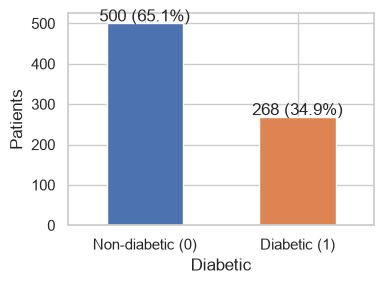

In [5]:
counts = df[config.TARGET].value_counts().sort_index()
ax = counts.plot.bar(color=["#4C72B0", "#DD8452"], figsize=(4, 3))
ax.set_xticklabels(["Non-diabetic (0)", "Diabetic (1)"], rotation=0)
ax.set_ylabel("Patients")
for i, v in enumerate(counts):
    ax.text(i, v + 5, f"{v} ({v / len(df):.1%})", ha="center")
plt.tight_layout()

About one patient in three is diabetic. Accuracy is a misleading metric here: always predicting
"non-diabetic" would already be about 65% accurate. The model therefore uses `class_weight="balanced"`
and is judged on ROC-AUC, PR-AUC and recall.

## Hidden missing values: impossible zeros

In [6]:
zero_counts = (df[config.ZERO_AS_MISSING] == 0).sum()
summary = pd.DataFrame({"zeros": zero_counts, "share": (zero_counts / len(df)).round(3)})
summary.sort_values("zeros", ascending=False)

,zeros,share
Insulin,374,0.487
SkinThickness,227,0.296
BloodPressure,35,0.046
BMI,11,0.014
Glucose,5,0.007


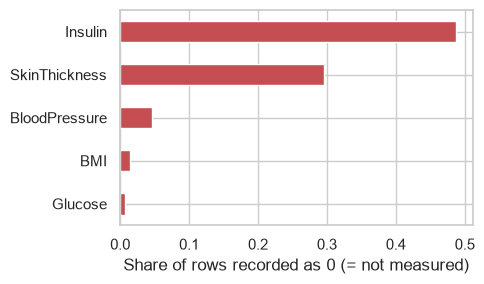

In [7]:
ax = summary["share"].sort_values().plot.barh(figsize=(5, 3), color="#C44E52")
ax.set_xlabel("Share of rows recorded as 0 (= not measured)")
plt.tight_layout()

Insulin is missing for about half of the patients and SkinThickness for about a third. Treating these zeros
as real measurements would tell the model that half the patients have zero insulin. They are converted
to NaN and imputed inside the Pipeline.

Is missingness itself informative? Compare the diabetic rate when a value is missing vs present:

In [8]:
X = replace_invalid_zeros(df[config.FEATURES])
rows = []
for col in config.ZERO_AS_MISSING:
    missing = X[col].isna()
    rows.append({
        "feature": col,
        "n_missing": int(missing.sum()),
        "diabetic_rate_if_missing": df.loc[missing, config.TARGET].mean(),
        "diabetic_rate_if_present": df.loc[~missing, config.TARGET].mean(),
    })
pd.DataFrame(rows).set_index("feature").round(3)

,n_missing,diabetic_rate_if_missing,diabetic_rate_if_present
feature,,,
Glucose,5,0.400,0.349
BloodPressure,35,0.457,0.344
SkinThickness,227,0.388,0.333
Insulin,374,0.369,0.330
BMI,11,0.182,0.351


## Feature distributions by class (zeros shown as missing)

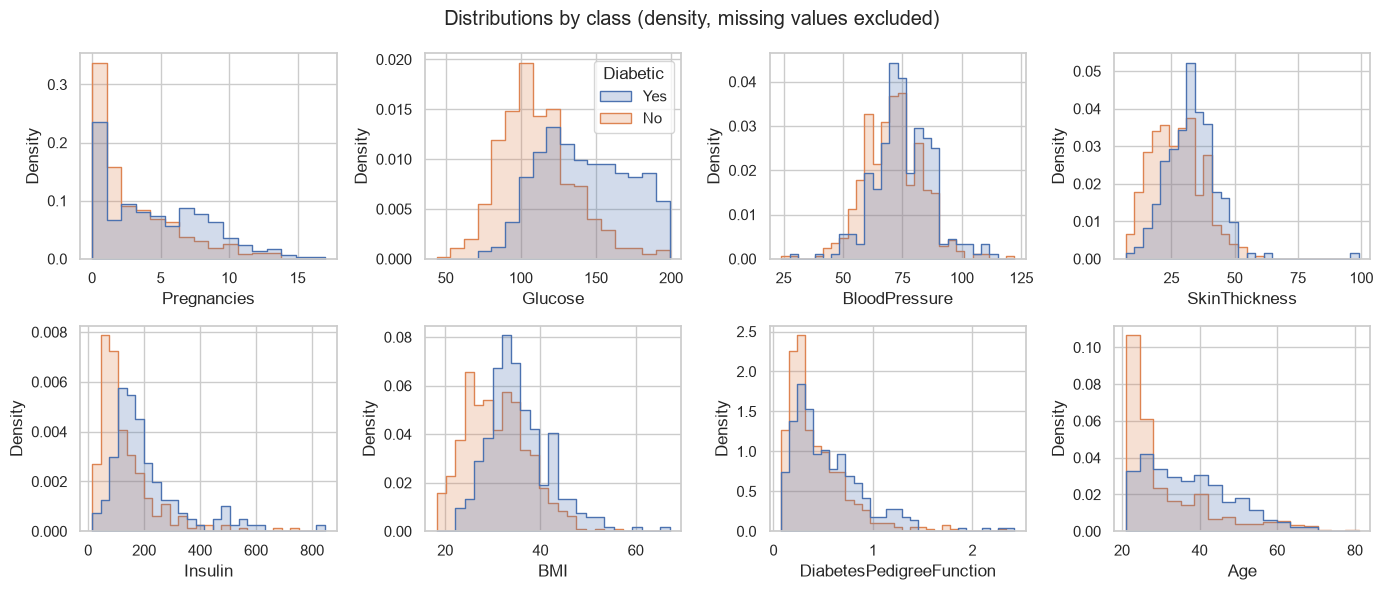

In [9]:
data = X.assign(Diabetic=df[config.TARGET].map({0: "No", 1: "Yes"}))
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), config.FEATURES):
    sns.histplot(data=data, x=col, hue="Diabetic", stat="density", common_norm=False,
                 element="step", ax=ax, legend=(col == "Glucose"))
fig.suptitle("Distributions by class (density, missing values excluded)")
plt.tight_layout()

In [10]:
X.groupby(df[config.TARGET]).median().T.rename(columns={0: "median_non_diabetic", 1: "median_diabetic"}).round(2)

Diabetic,median_non_diabetic,median_diabetic
Pregnancies,2.00,4.00
Glucose,107.00,140.00
BloodPressure,70.00,74.50
SkinThickness,27.00,32.00
Insulin,102.50,169.50
BMI,30.10,34.30
DiabetesPedigreeFunction,0.34,0.45
Age,27.00,36.00


## Correlations
Spearman (rank) correlation, missing values excluded pairwise, because several features are skewed
(Insulin, DiabetesPedigreeFunction, Age).

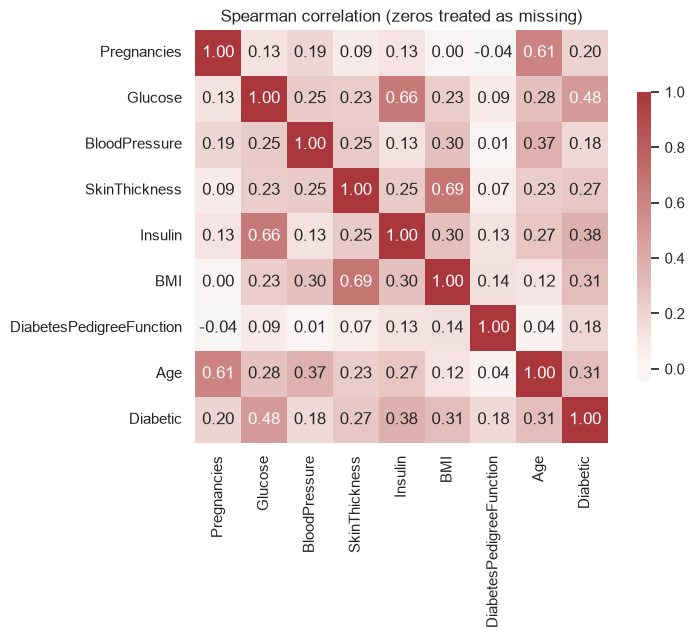

In [11]:
corr = X.assign(Diabetic=df[config.TARGET]).corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Spearman correlation (zeros treated as missing)")
plt.tight_layout()

In [12]:
corr[config.TARGET].drop(config.TARGET).sort_values(ascending=False).round(3)

Glucose                     0.483
Insulin                     0.377
BMI                         0.309
Age                         0.309
SkinThickness               0.265
Pregnancies                 0.199
BloodPressure               0.177
DiabetesPedigreeFunction    0.175
Name: Diabetic, dtype: float64

## Takeaways
(All numbers below come from the outputs above.)

1. **Imbalance:** 34.9% of patients are diabetic, so I report ROC-AUC, PR-AUC and recall, not just
   accuracy, and use `class_weight="balanced"`.
2. **Hidden missing values are the main data-quality issue.** Insulin is 0 (not measured) for 48.7% of
   rows and SkinThickness for 29.6%. These become NaN and are imputed inside the Pipeline.
3. **Missingness is only weakly related to the outcome.** For example, the diabetic rate is 36.9% when
   Insulin is missing vs 33.0% when it is present. A "was-missing" indicator feature is a possible
   next experiment, not something the current model uses.
4. **Glucose is the strongest single signal** (Spearman 0.48 with the target; median 140 vs 107 mg/dL),
   followed by Insulin (0.38, but observed for only half the patients), BMI and Age (0.31 each).
5. **Several features are right-skewed** (Insulin, DiabetesPedigreeFunction, Age). That is why median
   imputation (robust to outliers) is the default, with KNN imputation compared during tuning.